In [63]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import imblearn
import shap

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("SHAP:", shap.__version__)
print("Environment ready!")

Python: c:\Users\admin\anaconda3\envs\machine-learning-task\python.exe
Pandas: 3.0.3
Scikit-learn: 1.9.0
XGBoost: 3.4.1
Imbalanced-learn: 0.14.2
SHAP: 0.54.1
Environment ready!


![Customer Churn Analytics Dashboard](Customer%20Churn%20Analytics%20Dashboard.png)

# Customer Churn Root-Cause and Risk Scoring Analysis

## 1. Business Understanding

### 1.1 Business Problem

Customer churn occurs when customers stop using a company's services. High churn can reduce recurring revenue, increase customer acquisition costs, and weaken long-term customer relationships.

This project analyzes telecommunications customer data to identify characteristics associated with churn, develop machine learning models that estimate churn risk, and generate insights that could support evidence-based customer retention decisions.

The goal is to understand customer churn patterns, identify customers who may be at greater risk of leaving, and explore how predictive analytics can help a telecommunications business prioritize retention efforts.

### 1.2 Stakeholders

As this is an independent portfolio project, no company stakeholders have been formally engaged. The following are potential stakeholders who could benefit from the analysis in a real telecommunications business.

| Stakeholder | Role and Responsibilities | Interest in the Project |
|---|---|---|
| Customer Retention Manager | Plans and coordinates customer retention activities. | Uses churn-risk insights to prioritize retention efforts and reduce customer loss. |
| Customer Service Team | Handles customer inquiries, complaints, and service-related issues. | Identifies customers who may need support and investigates potential reasons for dissatisfaction. |
| Marketing Team | Develops customer engagement and retention campaigns. | Uses customer segments and churn patterns to inform targeted campaigns. |
| Data Science Team | Prepares data, develops models, evaluates performance, and interprets results. | Builds reliable churn prediction models and explains their predictive patterns. |
| Business Management | Sets business priorities and allocates resources. | Uses findings to inform retention strategy and resource allocation. |

These stakeholders are proposed for this project. Their involvement and the business benefits described have not been independently confirmed.

### 1.3 Project Objectives

The objectives of this project are to:

- Explore customer demographics, account information, subscribed services, contract types, tenure, and billing characteristics.
- Identify customer characteristics and service patterns associated with churn.
- Prepare the dataset for machine learning.
- Compare Random Forest and XGBoost classification models.
- Evaluate model performance using precision, recall, F1-score, and ROC-AUC.
- Generate customer-level churn probability scores and categorize customers into risk tiers.
- Interpret important model features and develop evidence-based retention recommendations.
- Document the project's limitations and potential business applications.

### 1.4 Project Scope

**Included in the project**

- Exploratory data analysis of the telecommunications customer churn dataset.
- Investigation of churn patterns across customer and service characteristics.
- Data cleaning, preprocessing, and feature preparation.
- Training and comparison of Random Forest and XGBoost models.
- Model evaluation using appropriate classification metrics.
- Generation of churn probabilities and low-, medium-, and high-risk categories.
- Interpretation of model results and formulation of potential retention recommendations.

**Excluded from the project**

- Deploying the model into a live production environment.
- Integrating with customer relationship management (CRM) systems.
- Contacting customers or implementing actual retention campaigns.
- Calculating verified financial savings without appropriate business cost and revenue data.
- Treating predictive feature importance as proof of causal relationships.

### 1.5 Business Questions

This project seeks to answer the following questions:

1. What proportion of customers in the dataset have churned?
2. Which customer characteristics, contract types, and subscribed services are associated with churn?
3. How effectively can machine learning models identify customers who churned in the observed data?
4. Which model performs better based on precision, recall, F1-score, and ROC-AUC?
5. Which customers receive high predicted churn-risk scores?
6. How could a telecommunications business use these insights to prioritize and evaluate customer retention activities?

### 1.6 Success Criteria

The project will be considered successful if it:

- Establishes a clear understanding of the dataset and observed churn patterns.
- Develops a reproducible preprocessing and modeling workflow.
- Compares Random Forest and XGBoost using a consistent evaluation strategy.
- Evaluates performance with particular attention to churn-class recall and F1-score, while also considering precision and ROC-AUC.
- Produces interpretable churn-risk scores and clearly defined risk categories.
- Identifies predictive patterns that can inform further business investigation.
- Documents limitations and avoids unsupported causal or financial claims.

The final model will be selected based on evaluation results rather than assuming that one algorithm will perform best.

### 1.7 Constraints and Assumptions

**Constraints**

- The analysis is limited to the variables and records available in the provided dataset.
- The dataset may not fully represent all telecommunications customers or current market conditions.
- Company-specific retention budgets, intervention costs, and customer lifetime value information are not available for this project.
- Class imbalance, data quality, and model assumptions may affect prediction performance.
- Predicted churn probabilities represent estimated risk, not certainty about future customer behavior.
- Model performance on historical evaluation data may differ from performance on future customers.

**Assumptions**

- The `Churn` variable represents the observed churn outcome recorded in the dataset.
- Customer demographics, account information, and service characteristics may contain useful predictive patterns.
- Historical patterns can provide a starting point for estimating churn risk, subject to appropriate validation.
- Retention recommendations generated from the analysis are proposals that would require business evaluation and testing.
- Predictive associations do not necessarily establish the causes of customer churn.

### 1.8 Expected Business Value

This project aims to demonstrate how customer analytics and machine learning can support more informed retention decisions.

Potential business benefits include:

- Understanding customer segments with higher observed churn.
- Identifying customer characteristics associated with churn.
- Prioritizing customers for further investigation using predicted risk scores.
- Supporting the design of targeted retention experiments.
- Providing a structured approach for measuring the effectiveness of future retention activities.

These benefits are potential outcomes rather than measured financial results. Actual business value would depend on model performance, the effectiveness of retention interventions, and their implementation costs.

### 1.9 Methodology

The project follows the **Cross-Industry Standard Process for Data Mining (CRISP-DM)** framework:

1. **Business Understanding:** Define the business problem, objectives, stakeholders, scope, and success criteria.
2. **Data Understanding:** Load and inspect the dataset, examine its structure, assess data quality, and explore churn patterns.
3. **Data Preparation:** Clean the data, handle missing or invalid values, encode categorical variables, and prepare the features for modeling.
4. **Modeling:** Train and compare Random Forest and XGBoost classification models.
5. **Evaluation:** Compare model performance, interpret results, and assess whether the models meet the project's success criteria.
6. **Deployment Planning:** Document how the analysis and predictions could support future retention decisions. Actual model deployment is outside the scope of this project.

# 2. Data Understanding

## 2.1 Loading the Dataset

The purpose of this phase is to understand the structure and quality of the telecommunications customer dataset before performing data cleaning, exploratory analysis, and machine learning.

In [64]:
from pathlib import Path
import pandas as pd

# Define the dataset path
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Confirm the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found. Expected location: {DATA_PATH.resolve()}"
    )

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Number of rows: 7,043
Number of columns: 21


### 2.2 Inspecting the Dataset

In [65]:
# Display the first five rows of the dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [66]:
#display the last five rows of the dataset
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [67]:
#inspect the data types of each column
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [68]:
#descriptive statistics of the dataset
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [69]:
#inspect information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [70]:
#checking for column
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [71]:
#checking dataset shape
df.shape

(7043, 21)

### 2.3 Checking Data Quality

In [72]:
#checking for columns with missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [73]:
#checking for duplicate rows in the dataset
duplicate_rows = df.duplicated().sum()
print("Duplicate rows in the dataset:")
print(duplicate_rows)

Duplicate rows in the dataset:
0


In [74]:
# Check unique customer IDs and repeated IDs

total_records = len(df)
unique_customers = df["customerID"].nunique()
repeated_ids = df["customerID"].duplicated().sum()

print("Total customer records:", total_records)
print("Unique customer IDs:", unique_customers)
print("Repeated customer IDs:", repeated_ids)

Total customer records: 7043
Unique customer IDs: 7043
Repeated customer IDs: 0


### 2.4 Understanding the Target Variable

In [75]:
# Count customers who churned and those who stayed
churn_counts = df["Churn"].value_counts()

print("Customer churn counts:")
print(churn_counts)

# Calculate percentages
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nCustomer churn percentages:")
print(churn_percentages.round(2))

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Summary of Customer Churn Distribution

The dataset contains 7,043 customers, of whom 5,174 (73.46%) did not churn, while 1,869 (26.54%) churned. This indicates that approximately one in four customers left the telecommunications company.

The target variable, Churn, is imbalanced because the number of customers who stayed is considerably higher than the number who churned. This imbalance is important during model development and evaluation, as accuracy alone may not adequately measure the model's ability to identify customers who churn. Therefore, precision, recall, F1-score, and ROC-AUC will be considered when comparing the classification models.

### 2.5 Visualizing the Churn Distribution

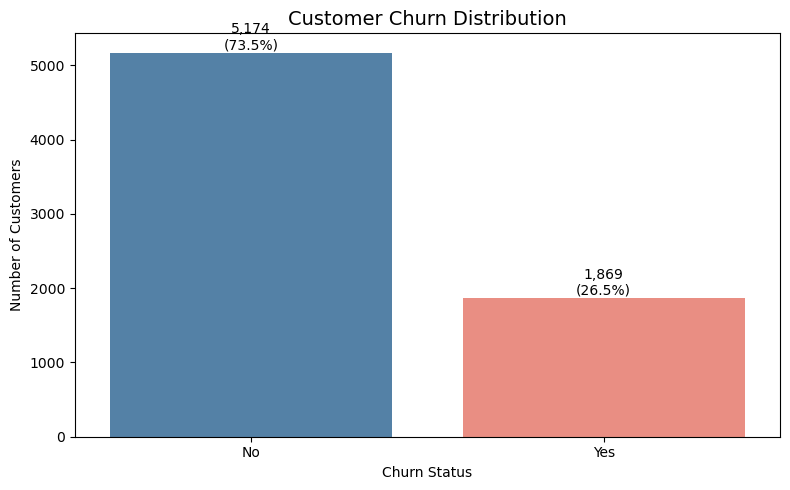

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=14)
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

# Display count and percentage above each bar
total = len(df)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = count / total * 100

    ax.annotate(
        f"{count:,}\n({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 2.6 Statistical Summary of Numerical Variables

In [77]:
# Summary statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Interpretation of Numerical Variables

The numerical summary provides an overview of customer tenure, monthly charges, and senior citizen status.

- **SeniorCitizen:** The mean is approximately 0.162, indicating that about 16.21% of customers are classified as senior citizens, assuming the variable is encoded as 1 for senior citizens and 0 otherwise.
- **Tenure:** The average customer tenure is approximately 32.37 months, with a median of 29 months. Tenure ranges from 0 to 72 months, indicating differences in the length of customer relationships.
- **MonthlyCharges:** The average monthly charge is approximately 64.76, while the median is 70.35. Monthly charges range from 18.25 to 118.75.

These statistics provide an initial understanding of customer characteristics and billing patterns. Further analysis is needed to determine how these variables relate to churn.

In [78]:
# Summarize categorical and text columns
df.describe(include=["str", "object"])

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


### Interpretation of Categorical Variables

The categorical summary provides an overview of the customer demographics, subscribed services, contract types, payment methods, and churn status.

- **Gender:** The dataset contains two categories, Male and Female. Male is the most frequent category, with 3,555 customers.
- **Partner and Dependents:** The most frequent category for both variables is No, with 3,641 customers reporting no partner and 4,933 customers reporting no dependents.
- **PhoneService:** Most customers have phone service, with 6,361 records in the Yes category.
- **InternetService:** Fiber optic is the most frequent internet service category, appearing in 3,096 records.
- **Contract:** Month-to-month is the most frequent contract type, with 3,875 customers.
- **PaymentMethod:** Electronic check is the most frequent payment method, with 2,365 customers.
- **Churn:** No is the most frequent category, appearing in 5,174 records, consistent with the earlier churn distribution analysis.
- **TotalCharges:** Although this column represents a numeric quantity, it is currently treated as a text column. It contains 6,531 unique values, suggesting that its data type should be investigated before modeling.

These findings describe the dataset's categorical distributions. Further analysis is needed to determine how these characteristics relate to customer churn.

### 2.7 Investigating Potential Data-Quality Issues

In [79]:
# Check the data type of TotalCharges
print("TotalCharges data type:", df["TotalCharges"].dtype)

# Check for values that are blank or contain only whitespace
blank_total_charges = df["TotalCharges"].astype("str").str.strip().eq("").sum()

print("Blank TotalCharges values:", blank_total_charges)

TotalCharges data type: str
Blank TotalCharges values: 11


In [80]:
# Display records where TotalCharges is blank or whitespace-only
blank_mask = df["TotalCharges"].str.strip().eq("")

display(df.loc[blank_mask])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


### Interpretation of Blank TotalCharges Records

The investigation identified 11 records with blank or whitespace-only values in the `TotalCharges` column. All 11 customers have a tenure of zero months and a recorded churn status of `No`.

This pattern suggests that the affected records may represent newly registered customers who have not yet accumulated total charges. However, the exact reason for the blank values cannot be confirmed from the dataset alone.

During Data Preparation, the `TotalCharges` column will be converted to a numeric data type, and the blank values will be handled using an appropriate strategy. The original dataset will be preserved to maintain data integrity.

In [81]:
# Check all unique values in the target variable
print("Unique Churn values:", df["Churn"].unique())

# Check for unexpected or inconsistent target labels
print("\nChurn value counts:")
print(df["Churn"].value_counts(dropna=False))

Unique Churn values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Churn value counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 2.8 Validation of the Target Variable

The `Churn` column contains two distinct categories: `No` and `Yes`. There are 5,174 customers labeled `No` and 1,869 customers labeled `Yes`, with no missing or unexpected target labels identified.

This confirms that the target variable is suitable for a binary classification task, subject to the remaining data preparation and validation steps. The observed class imbalance will be considered when training and evaluating the machine learning models.

### 2.9 Data Understanding Summary

The initial exploration identified the following characteristics of the Telco Customer Churn dataset:

- **Dataset size:** 7,043 customer records and 21 columns.
- **Target variable:** `Churn`, containing two classes: `Yes` and `No`.
- **Churn distribution:** 1,869 customers (26.54%) churned, while 5,174 (73.46%) remained.
- **Missing values:** The initial missing-value check found no conventional missing values, but further investigation identified 11 blank `TotalCharges` entries.
- **Duplicate records:** No duplicate rows or repeated customer IDs were identified.
- **Data quality:** The 11 blank `TotalCharges` entries belong to customers with a tenure of zero. These require careful handling during data preparation.
- **Potential modelling consideration:** The target classes are imbalanced, so model evaluation should consider precision, recall, F1-score, and ROC-AUC alongside accuracy.

The dataset is suitable for further analysis, subject to appropriate data preparation and validation. The next phase will address data types, blank values, feature preparation, and the prevention of data leakage.

## 3. Data Preparation

### 3.1 Data Preparation Objectives

The objective of this phase is to transform the raw Telco Customer Churn dataset into a clean, consistent, and modelling-ready dataset while preserving the information needed for analysis.

The following tasks will be completed:

- Inspect and correct data types.
- Investigate and handle blank values in `TotalCharges`.
- Separate the customer identifier from the predictive features.
- Encode categorical variables into a format suitable for machine learning.
- Prepare the target variable, `Churn`.
- Split the data into training and testing sets.
- Prevent data leakage by fitting preprocessing steps using the training data only.
- Document all preparation decisions and validate the prepared dataset.

Data preparation will be performed on a working copy of the original dataset so that the raw data remains unchanged.

In [82]:
# Inspect the data types before data preparation
print("Data types before preparation:")
print(df.dtypes)

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nExamples of TotalCharges values:")
print(df["TotalCharges"].head(10).tolist())

Data types before preparation:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

TotalCharges data type:
str

Examples of TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']


In [83]:
# Create a working copy; preserve the original dataset
df_clean = df.copy()

# Remove leading and trailing spaces from TotalCharges
df_clean["TotalCharges"] = df_clean["TotalCharges"].str.strip()

# Identify blank TotalCharges values
blank_total_charges = df_clean["TotalCharges"].eq("")

print("Blank TotalCharges values:", blank_total_charges.sum())

# Inspect affected customers
display(
    df_clean.loc[
        blank_total_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Blank TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### Convert TotalCharges to numeric

In [84]:
import numpy as np
import pandas as pd
# Convert TotalCharges from text to numeric
# Blank strings will become NaN
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check the conversion results
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)
print("Missing TotalCharges values:", df_clean["TotalCharges"].isna().sum())
print("Total rows retained:", len(df_clean))

# Inspect the affected records
display(
    df_clean.loc[
        df_clean["TotalCharges"].isna(),
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

TotalCharges data type: float64
Missing TotalCharges values: 11
Total rows retained: 7043


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


### Validate the cleaned dataset

In [85]:
# Check missing values in every column
missing_values = df_clean.isna().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df_clean.isna().sum().sum())

# Confirm dataset dimensions
print("\nDataset shape:", df_clean.shape)

# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())

Missing values by column:
TotalCharges    11
dtype: int64

Total missing values: 11

Dataset shape: (7043, 21)
Duplicate rows: 0
Duplicate customer IDs: 0


### Inspect categorical variables

In [86]:
# Inspect categorical columns without the Pandas warning

categorical_columns = df_clean.select_dtypes(
    include=["str", "object", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts(dropna=False))


customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

### Separate the Customer ID and Target Variable

In [87]:
# Separate the target variable and customer ID

# Store customer IDs separately
customer_ids = df_clean["customerID"].copy()

# Separate the target variable
y = df_clean["Churn"].copy()

# Create the feature dataset
X = df_clean.drop(columns=["customerID", "Churn"]).copy()

# Display the results
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("Customer IDs shape:", customer_ids.shape)

print("\nTarget variable distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Features (X) shape: (7043, 19)
Target (y) shape: (7043,)
Customer IDs shape: (7043,)

Target variable distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


### Split the Data into Training and Testing Sets

In [88]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Compare churn proportions
print("\nChurn proportions in the full dataset:")
print(y.value_counts(normalize=True).round(4))

print("\nChurn proportions in the training set:")
print(y_train.value_counts(normalize=True).round(4))

print("\nChurn proportions in the testing set:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (5634, 19)
Testing features: (1409, 19)
Training target: (5634,)
Testing target: (1409,)

Churn proportions in the full dataset:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

Churn proportions in the training set:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

Churn proportions in the testing set:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


### Identify Numerical and Categorical Features

In [89]:
# Identify numerical and categorical features

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

print("\nTotal features identified:",
      len(numerical_features) + len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15

Total features identified: 19


### Build the Preprocessing Pipeline

In [90]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")
print("\nNumerical pipeline:")
print(numerical_pipeline)

print("\nCategorical pipeline:")
print(categorical_pipeline)

print("\nCombined preprocessor:")
print(preprocessor)

Preprocessing pipeline created successfully.

Numerical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Categorical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])

Combined preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                               

### Build the First Machine Learning Model

In [91]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create a complete pipeline:
# preprocessing followed by model training
logistic_regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Complete Logistic Regression pipeline created.")

Complete Logistic Regression pipeline created.


### Train the model

In [92]:
# Train the complete pipeline using training data only
logistic_regression_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### Evaluate the Trained Logistic Regression Model

In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict churn on unseen test data
y_pred = logistic_regression_pipeline.predict(X_test)

# Predict churn probabilities
y_prob = logistic_regression_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("LOGISTIC REGRESSION — TEST RESULTS")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label='Yes'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label='Yes'):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, pos_label='Yes'):.4f}")
print(f"ROC-AUC:   {roc_auc_score((y_test == 'Yes').astype(int), y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

LOGISTIC REGRESSION — TEST RESULTS
----------------------------------------
Accuracy:  0.7381
Precision: 0.5043
Recall:    0.7834
F1-score:  0.6136
ROC-AUC:   0.8413

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[747 288]
 [ 81 293]]


Key interpretation: Logistic Regression identifies approximately 78% of actual churners, which is useful when the business wants to avoid missing customers who may leave. However, its precision is around 50%, so many customers flagged as potential churners do not actually churn.

Out of 374 actual churners, the model identifies 293 and misses 81. It also flags 288 customers who did not churn. This highlights the trade-off between detecting more churners and avoiding unnecessary retention campaigns.

### Logistic Regression — Baseline Evaluation

The Logistic Regression model achieved 73.81% accuracy, 50.43% precision, 78.34% recall, an F1-score of 61.36%, and a ROC-AUC of 84.13% on the test set.

The model identified 293 of the 374 customers who churned, while missing 81 actual churners. However, it also generated 288 false-positive predictions. These results suggest that the model is reasonably effective at identifying potential churners, but its precision indicates that further improvements may be needed.

This model will serve as the baseline for comparison with Decision Tree, Random Forest, and XGBoost. The final model will be selected using multiple evaluation metrics and the business objective of identifying customers at risk of leaving.

### Train the Decision Tree model

In [94]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create the complete Decision Tree pipeline
decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
        max_depth=5
    ))
])

# Train the model
decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


### Evaluate the Decision Tree Model

In [95]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predictions on training and test data
y_train_pred_dt = decision_tree_pipeline.predict(X_train)
y_test_pred_dt = decision_tree_pipeline.predict(X_test)

# Churn probabilities for ROC-AUC
y_train_prob_dt = decision_tree_pipeline.predict_proba(X_train)[:, 1]
y_test_prob_dt = decision_tree_pipeline.predict_proba(X_test)[:, 1]

# Helper function to calculate metrics
def evaluate_model(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, pos_label="Yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_true == "Yes").astype(int), y_prob
        )
    }

# Compare training and test performance
dt_train_metrics = evaluate_model(
    y_train, y_train_pred_dt, y_train_prob_dt
)
dt_test_metrics = evaluate_model(
    y_test, y_test_pred_dt, y_test_prob_dt
)

print("DECISION TREE — TRAINING RESULTS")
for metric, score in dt_train_metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nDECISION TREE — TEST RESULTS")
for metric, score in dt_test_metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nClassification Report — Test Set")
print(classification_report(y_test, y_test_pred_dt))

print("Confusion Matrix — Test Set")
print(confusion_matrix(y_test, y_test_pred_dt, labels=["No", "Yes"]))

DECISION TREE — TRAINING RESULTS
Accuracy: 0.7636
Precision: 0.5371
Recall: 0.7900
F1-score: 0.6394
ROC-AUC: 0.8524

DECISION TREE — TEST RESULTS
Accuracy: 0.7551
Precision: 0.5269
Recall: 0.7594
F1-score: 0.6221
ROC-AUC: 0.8323

Classification Report — Test Set
              precision    recall  f1-score   support

          No       0.90      0.75      0.82      1035
         Yes       0.53      0.76      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409

Confusion Matrix — Test Set
[[780 255]
 [ 90 284]]


### Decision Tree — Evaluation and Generalization

The Decision Tree achieved 75.51% test accuracy, 52.69% precision, 75.94% recall, an F1-score of 62.21%, and a ROC-AUC of 83.23%.

The model correctly identified 284 of the 374 actual churners and missed 90. Compared with Logistic Regression, it achieved higher test accuracy, precision, and F1-score, while Logistic Regression achieved higher recall and ROC-AUC.

The relatively small differences between the Decision Tree's training and test scores suggest reasonable generalization, with no strong evidence of overfitting from the metrics examined. Further comparison with Random Forest and XGBoost is required before selecting the final model.

### Train the Random Forest model

In [96]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the complete Random Forest pipeline
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


###  Evaluate the Random Forest Model
Evaluate training and test performance

In [97]:
# Generate predictions on training and test data
y_train_pred_rf = random_forest_pipeline.predict(X_train)
y_test_pred_rf = random_forest_pipeline.predict(X_test)

# Generate churn probabilities for ROC-AUC
y_train_prob_rf = random_forest_pipeline.predict_proba(X_train)[:, 1]
y_test_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
rf_train_metrics = evaluate_model(
    y_train, y_train_pred_rf, y_train_prob_rf
)

rf_test_metrics = evaluate_model(
    y_test, y_test_pred_rf, y_test_prob_rf
)

# Display training results
print("RANDOM FOREST — TRAINING RESULTS")
print("-" * 40)

for metric, score in rf_train_metrics.items():
    print(f"{metric}: {score:.4f}")

# Display test results
print("\nRANDOM FOREST — TEST RESULTS")
print("-" * 40)

for metric, score in rf_test_metrics.items():
    print(f"{metric}: {score:.4f}")

RANDOM FOREST — TRAINING RESULTS
----------------------------------------
Accuracy: 0.9940
Precision: 0.9778
Recall: 1.0000
F1-score: 0.9888
ROC-AUC: 1.0000

RANDOM FOREST — TEST RESULTS
----------------------------------------
Accuracy: 0.7637
Precision: 0.5485
Recall: 0.6203
F1-score: 0.5822
ROC-AUC: 0.8225


### Random Forest — Evaluation and Generalization

The Random Forest model achieved 76.37% test accuracy, 54.85% precision, 62.03% recall, an F1-score of 58.22%, and a ROC-AUC of 82.25%.

Training performance was substantially higher, with a training F1-score of 98.88% and ROC-AUC of 100.00%. The large difference between training and test scores indicates substantial overfitting.

Although the model achieves reasonable test ROC-AUC, its recall and F1-score suggest that its current classification performance needs improvement. Potential remedies include limiting tree depth, increasing minimum leaf size, and tuning hyperparameters using cross-validation.

The model will remain in the comparison until all four baseline models have been evaluated.

### Check for underfitting and overfitting

In [98]:
# Compare training and test performance
print("RANDOM FOREST — GENERALIZATION CHECK")
print("-" * 45)

for metric in ["F1-score", "ROC-AUC"]:
    train_score = rf_train_metrics[metric]
    test_score = rf_test_metrics[metric]
    gap = train_score - test_score

    print(f"\n{metric}")
    print(f"Training score: {train_score:.4f}")
    print(f"Test score:     {test_score:.4f}")
    print(f"Train-test gap: {gap:.4f}")

RANDOM FOREST — GENERALIZATION CHECK
---------------------------------------------

F1-score
Training score: 0.9888
Test score:     0.5822
Train-test gap: 0.4066

ROC-AUC
Training score: 1.0000
Test score:     0.8225
Train-test gap: 0.1775


### Train a regularized Random Forest

In [99]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a regularized Random Forest pipeline
random_forest_regularized = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the regularized model
random_forest_regularized.fit(X_train, y_train)

print("Regularized Random Forest trained successfully.")

Regularized Random Forest trained successfully.


### Evaluate training and test performance

In [100]:
# Generate predictions
y_train_pred_rf_reg = random_forest_regularized.predict(X_train)
y_test_pred_rf_reg = random_forest_regularized.predict(X_test)

# Generate churn probabilities
y_train_prob_rf_reg = (
    random_forest_regularized.predict_proba(X_train)[:, 1]
)
y_test_prob_rf_reg = (
    random_forest_regularized.predict_proba(X_test)[:, 1]
)

# Calculate metrics using the existing evaluation function
rf_reg_train_metrics = evaluate_model(
    y_train, y_train_pred_rf_reg, y_train_prob_rf_reg
)

rf_reg_test_metrics = evaluate_model(
    y_test, y_test_pred_rf_reg, y_test_prob_rf_reg
)

# Compare training and test performance
print("REGULARIZED RANDOM FOREST — TRAINING")
for metric, score in rf_reg_train_metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nREGULARIZED RANDOM FOREST — TEST")
for metric, score in rf_reg_test_metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nGENERALIZATION CHECK")
for metric in ["F1-score", "ROC-AUC"]:
    train_score = rf_reg_train_metrics[metric]
    test_score = rf_reg_test_metrics[metric]

    print(f"\n{metric}")
    print(f"Training: {train_score:.4f}")
    print(f"Test:     {test_score:.4f}")
    print(f"Gap:      {train_score - test_score:.4f}")

REGULARIZED RANDOM FOREST — TRAINING
Accuracy: 0.7930
Precision: 0.5734
Recall: 0.8595
F1-score: 0.6879
ROC-AUC: 0.8965

REGULARIZED RANDOM FOREST — TEST
Accuracy: 0.7551
Precision: 0.5253
Recall: 0.8048
F1-score: 0.6357
ROC-AUC: 0.8433

GENERALIZATION CHECK

F1-score
Training: 0.6879
Test:     0.6357
Gap:      0.0522

ROC-AUC
Training: 0.8965
Test:     0.8433
Gap:      0.0531


### Regularized Random Forest — Evaluation and Generalization

The regularized Random Forest achieved 75.51% test accuracy, 52.53% precision, 80.48% recall, an F1-score of 63.57%, and a ROC-AUC of 84.33%.

Compared with the original Random Forest, regularization substantially reduced the training–test performance gap. The F1-score gap decreased from 40.66 to 5.22 percentage points, while the ROC-AUC gap decreased from 17.75 to 5.31 percentage points.

Test recall improved from 62.03% to 80.48%, and test F1-score improved from 58.22% to 63.57%. Although accuracy and precision decreased slightly, the regularized model identifies more actual churners and generalizes better to unseen data.

These results suggest that restricting tree complexity was beneficial. The model will be retained for comparison with Logistic Regression, Decision Tree, and XGBoost.

### Train XGBoost

In [101]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# Create the XGBoost pipeline
xgboost_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Convert target labels to numeric values
y_train_xgb = (y_train == "Yes").astype(int)

# Train XGBoost
xgboost_pipeline.fit(X_train, y_train_xgb)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


### Evaluate the XGBoost Model

In [102]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# 1. Convert actual churn labels to numeric values
# No = 0, Yes = 1
y_train_xgb = (y_train == "Yes").astype(int)
y_test_xgb = (y_test == "Yes").astype(int)

# 2. Generate predictions for training and test data
y_train_pred_xgb = xgboost_pipeline.predict(X_train)
y_test_pred_xgb = xgboost_pipeline.predict(X_test)

# 3. Generate predicted probabilities for churn
y_train_prob_xgb = xgboost_pipeline.predict_proba(X_train)[:, 1]
y_test_prob_xgb = xgboost_pipeline.predict_proba(X_test)[:, 1]

# 4. Define a function to calculate evaluation metrics
def evaluate_xgboost(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# 5. Calculate training metrics
xgb_train_metrics = evaluate_xgboost(
    y_train_xgb,
    y_train_pred_xgb,
    y_train_prob_xgb
)

# 6. Calculate test metrics
xgb_test_metrics = evaluate_xgboost(
    y_test_xgb,
    y_test_pred_xgb,
    y_test_prob_xgb
)

# 7. Display training results
print("XGBOOST — TRAINING RESULTS")
print("-" * 40)

for metric, score in xgb_train_metrics.items():
    print(f"{metric}: {score:.4f}")

# 8. Display test results
print("\nXGBOOST — TEST RESULTS")
print("-" * 40)

for metric, score in xgb_test_metrics.items():
    print(f"{metric}: {score:.4f}")

# 9. Display the test classification report
print("\nXGBOOST — TEST CLASSIFICATION REPORT")
print(
    classification_report(
        y_test_xgb,
        y_test_pred_xgb,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

# 10. Display the test confusion matrix
print("XGBOOST — TEST CONFUSION MATRIX")
print(
    confusion_matrix(
        y_test_xgb,
        y_test_pred_xgb,
        labels=[0, 1]
    )
)

# 11. Check for overfitting or underfitting
print("\nXGBOOST — GENERALIZATION CHECK")
print("-" * 45)

for metric in ["F1-score", "ROC-AUC"]:
    train_score = xgb_train_metrics[metric]
    test_score = xgb_test_metrics[metric]
    gap = train_score - test_score

    print(f"\n{metric}")
    print(f"Training score: {train_score:.4f}")
    print(f"Test score:     {test_score:.4f}")
    print(f"Train-test gap: {gap:.4f}")

XGBOOST — TRAINING RESULTS
----------------------------------------
Accuracy: 0.8335
Precision: 0.7248
Recall: 0.6007
F1-score: 0.6569
ROC-AUC: 0.8966

XGBOOST — TEST RESULTS
----------------------------------------
Accuracy: 0.8013
Precision: 0.6567
Recall: 0.5267
F1-score: 0.5846
ROC-AUC: 0.8447

XGBOOST — TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

XGBOOST — TEST CONFUSION MATRIX
[[932 103]
 [177 197]]

XGBOOST — GENERALIZATION CHECK
---------------------------------------------

F1-score
Training score: 0.6569
Test score:     0.5846
Train-test gap: 0.0723

ROC-AUC
Training score: 0.8966
Test score:     0.8447
Train-test gap: 0.0518


- Overfitting: There is a moderate training–test gap, but the results do not suggest the extreme overfitting seen in the original Random Forest.
- Underfitting: We cannot conclude that it is underfitting from these metrics alone. Its ROC-AUC is reasonably strong, though its current churn recall could be improved.
- Business concern: It detects only 197 of the 374 actual churners and misses 177. If identifying at-risk customers is our priority, this recall needs attention.

### Compare all model results

In [103]:
import pandas as pd

# Collect the test results from all models
model_comparison = pd.DataFrame({
    "Logistic Regression": {
        "Accuracy": 0.7381,
        "Precision": 0.5043,
        "Recall": 0.7834,
        "F1-score": 0.6136,
        "ROC-AUC": 0.8413
    },
    "Decision Tree": {
        "Accuracy": 0.7551,
        "Precision": 0.5269,
        "Recall": 0.7594,
        "F1-score": 0.6221,
        "ROC-AUC": 0.8323
    },
    "Random Forest (Original)": {
        "Accuracy": 0.7637,
        "Precision": 0.5485,
        "Recall": 0.6203,
        "F1-score": 0.5822,
        "ROC-AUC": 0.8225
    },
    "Random Forest (Regularized)": {
        "Accuracy": 0.7551,
        "Precision": 0.5253,
        "Recall": 0.8048,
        "F1-score": 0.6357,
        "ROC-AUC": 0.8433
    },
    "XGBoost": {
        "Accuracy": 0.8013,
        "Precision": 0.6567,
        "Recall": 0.5267,
        "F1-score": 0.5846,
        "ROC-AUC": 0.8447
    }
})

print("MODEL COMPARISON — TEST SET")
display(model_comparison.round(4).T.sort_values("ROC-AUC", ascending=False))

MODEL COMPARISON — TEST SET


,Accuracy,Precision,Recall,F1-score,ROC-AUC
XGBoost,0.8013,0.6567,0.5267,0.5846,0.8447
Random Forest (Regularized),0.7551,0.5253,0.8048,0.6357,0.8433
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
Decision Tree,0.7551,0.5269,0.7594,0.6221,0.8323
Random Forest (Original),0.7637,0.5485,0.6203,0.5822,0.8225


### 27.1 Model Comparison and Key Findings

Four machine learning algorithms were evaluated for customer churn prediction: Logistic Regression, Decision Tree, Random Forest, and XGBoost. The original and regularized versions of Random Forest were also compared to assess the impact of controlling model complexity.

The models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Training and test performance were compared to identify potential underfitting and overfitting.

**Key findings:**

- **Logistic Regression:** Achieved a test recall of 78.34% and ROC-AUC of 84.13%, providing a useful baseline for churn prediction.
- **Decision Tree:** Achieved a test F1-score of 62.21% and recall of 75.94%, with a relatively small training–test performance gap.
- **Original Random Forest:** Showed substantial overfitting, with a training F1-score of 98.88% compared with 58.22% on the test set.
- **Regularized Random Forest:** Improved generalization, achieving a test F1-score of 63.57%, recall of 80.48%, and ROC-AUC of 84.33%. Its training–test gaps were substantially smaller than those of the original model.
- **XGBoost:** Achieved the highest test accuracy of 80.13% and ROC-AUC of 84.47%, but its test recall was 52.67%, indicating that it missed a considerable proportion of actual churners.

### 27.2 Preliminary Conclusion

The regularized Random Forest is currently the strongest candidate when the primary objective is identifying customers at risk of churn, because it achieved the highest recall and F1-score among the evaluated models. XGBoost remains a competitive candidate due to its accuracy and ROC-AUC.

These results represent baseline performance using the current model settings and classification thresholds. No final model has been selected yet.

### 27.3 Next Steps

The next phase will focus on improving model performance through hyperparameter tuning and cross-validation. Regularized Random Forest and XGBoost will be prioritized for further investigation because they offer different strengths in churn detection and overall predictive performance.

The tuned models will be assessed for precision, recall, F1-score, ROC-AUC, and potential overfitting or underfitting. The classification threshold will also be considered to balance missed churners against false-positive predictions.

The held-out test set will be reserved for the final evaluation after model selection and tuning. The selected model will then be used for customer churn-risk scoring, model interpretation, and deployment.

### Stratified 5-Fold Cross-Validation

In [104]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create a new pipeline for tuning
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Define the hyperparameters to test
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12, None],
    "model__min_samples_split": [10, 20],
    "model__min_samples_leaf": [5, 10]
}

# Set up stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best settings using training data only
rf_grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

rf_grid_search.fit(X_train, y_train)

print("\nBest hyperparameters:")
print(rf_grid_search.best_params_)

print("\nBest mean cross-validation F1-score:")
print(round(rf_grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits


c:\Users\admin\anaconda3\envs\machine-learning-task\Lib\site-packages\sklearn\model_selection\_search.py:1234: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan]
  warnings.warn(
c:\Users\admin\anaconda3\envs\machine-learning-task\Lib\site-packages\sklearn\model_selection\_search.py:1234: UserWarning: One or more of the train scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan]
  warnings.warn(



Best hyperparameters:
{'model__max_depth': 8, 'model__min_samples_leaf': 5, 'model__min_samples_split': 10, 'model__n_estimators': 100}

Best mean cross-validation F1-score:
nan


In [116]:

# Hyperparameter Tuning: Regularized Random Forest
# Using Stratified 5-Fold Cross-Validation

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

# 1. Build the pipeline
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Define the hyperparameter grid
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12, None],
    "model__min_samples_split": [10, 20],
    "model__min_samples_leaf": [5, 10]
}

# 3. Set up stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Make F1-score treat "Yes" as the positive churn class
f1_churn_scorer = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

# 5. Run GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring=f1_churn_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    error_score="raise",
    return_train_score=True
)

# 6. Fit using training data only
rf_grid_search. fit(X_train, y_train)

# 7. Display the best results
print("\nBest hyperparameters:")
print(rf_grid_search.best_params_)

print("\nBest mean cross-validation F1-score:")
print(round(rf_grid_search.best_score_, 4))


Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best hyperparameters:
{'model__max_depth': 8, 'model__min_samples_leaf': 5, 'model__min_samples_split': 20, 'model__n_estimators': 100}

Best mean cross-validation F1-score:
0.6373


Tuned Random Forest — Test Results
----------------------------------------
Accuracy: 0.7495
Precision: 0.5185
Recall: 0.7888
F1-Score: 0.6257
ROC-AUC: 0.8422

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.74      0.81      1035
         Yes       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



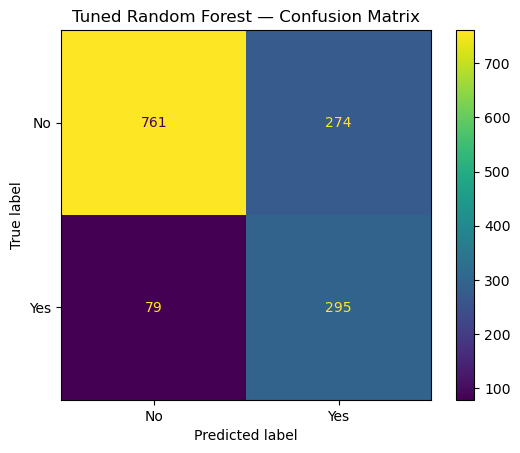

In [114]:
# Evaluate the Tuned Random Forest on the Test Set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Retrieve the best model from GridSearchCV
best_rf_model = rf_grid_search.best_estimator_

# Generate predictions on the untouched test set
y_pred_tuned_rf = best_rf_model.predict(X_test)

# Get probabilities for the positive class: "Yes"
y_prob_tuned_rf = best_rf_model.predict_proba(X_test)[:, 
    list(best_rf_model.named_steps["model"].classes_).index("Yes")
]

# Calculate evaluation metrics
tuned_rf_results = {
    "Accuracy": accuracy_score(y_test, y_pred_tuned_rf),
    "Precision": precision_score(
        y_test, y_pred_tuned_rf, pos_label="Yes", zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_tuned_rf, pos_label="Yes", zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_tuned_rf, pos_label="Yes", zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        (y_test == "Yes").astype(int), y_prob_tuned_rf
    )
}

print("Tuned Random Forest — Test Results")
print("-" * 40)

for metric, value in tuned_rf_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned_rf,
    labels=["No", "Yes"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_tuned_rf,
    labels=["No", "Yes"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot()

plt.title("Tuned Random Forest — Confusion Matrix")
plt.show()

### classification threshold analysis

In [ ]:
# Classification Threshold Analysis
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Use the tuned Random Forest's predicted probabilities
threshold_results = []

thresholds = np.arange(0.20, 0.71, 0.05)

for threshold in thresholds:
    y_pred_threshold = np.where(
        y_prob_tuned_rf >= threshold, "Yes", "No"
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, y_pred_threshold,
            pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold,
            pos_label="Yes", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_threshold,
            pos_label="Yes", zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("Threshold Analysis Results:")
display(threshold_df.round(4))

Threshold Analysis Results:


,Threshold,Precision,Recall,F1-Score
0,0.20,0.3720,0.9679,0.5375
1,0.25,0.4011,0.9492,0.5639
2,0.30,0.4235,0.9171,0.5794
3,0.35,0.4395,0.8743,0.5850
4,0.40,0.4679,0.8583,0.6057
5,0.45,0.4976,0.8262,0.6211
6,0.50,0.5185,0.7888,0.6257
7,0.55,0.5413,0.7353,0.6236
8,0.60,0.5670,0.6791,0.6180
9,0.65,0.5995,0.6203,0.6097


Lower threshold (0.20): catches almost all churners, but flags many customers who will not churn.



Threshold 0.50: gives the best balance of precision and recall according to F1-score in your tested range.



Higher threshold (0.70): predictions are more precise, but the model misses more actual churners.

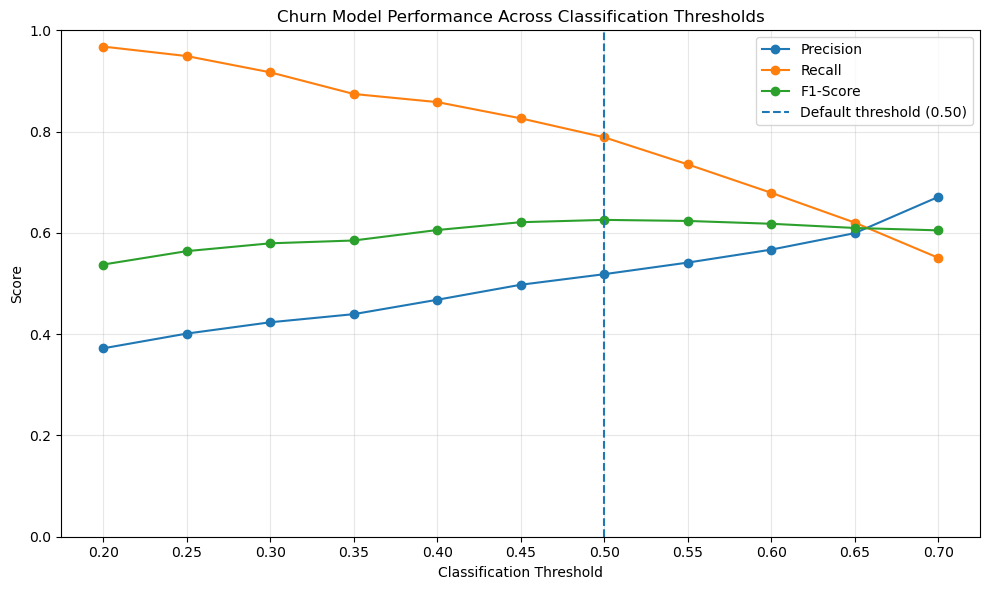

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default threshold (0.50)"
)

plt.title("Churn Model Performance Across Classification Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.xticks(threshold_df["Threshold"])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Importance
36,cat__Contract_Month-to-month,0.1508
1,num__tenure,0.1240
3,num__TotalCharges,0.0861
18,cat__OnlineSecurity_No,0.0747
38,cat__Contract_Two year,0.0723
27,cat__TechSupport_No,0.0639
16,cat__InternetService_Fiber optic,0.0581
2,num__MonthlyCharges,0.0545
43,cat__PaymentMethod_Electronic check,0.0411
21,cat__OnlineBackup_No,0.0206


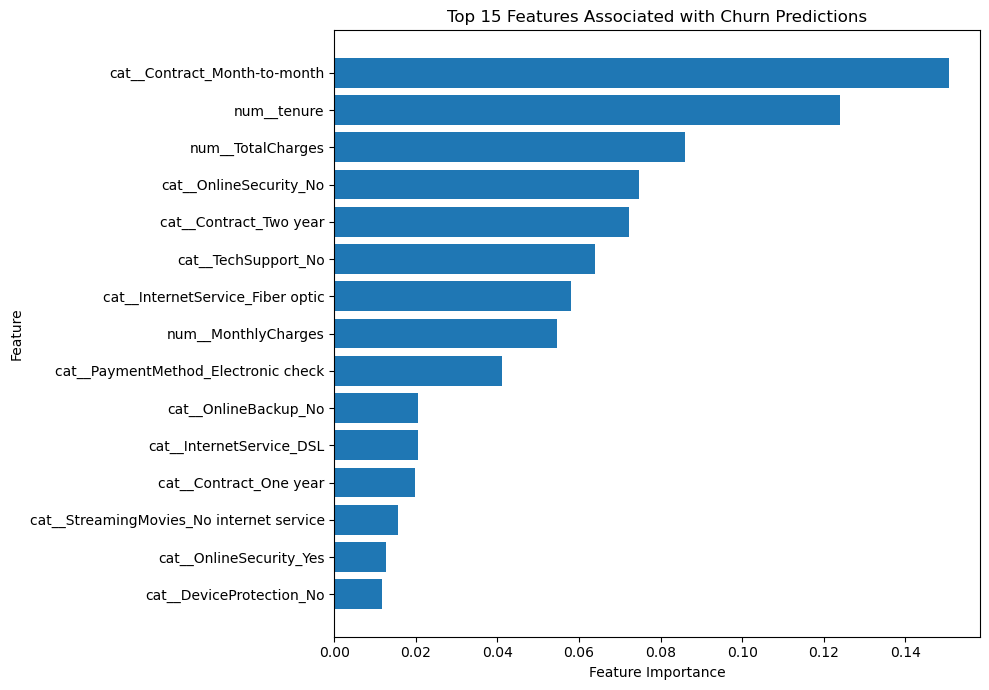

In [ ]:
# Feature Importance Analysis — Regularized Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# Extract the trained Random Forest model
rf_model = random_forest_regularized.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    random_forest_regularized
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create a feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Rank the features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
display(feature_importance.head(15).round(4))

# Visualize the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features Associated with Churn Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

What the results mean for the business
1. Contract type: Month-to-month contracts have the highest importance (0.1508). Customers on these contracts may be a priority group for retention campaigns.
2. Tenure: Tenure ranks second (0.1240). Customer loyalty and the length of the customer relationship are important to the model's predictions.
3. Total charges: This ranks third (0.0861). It may partly reflect tenure and customers' accumulated spending.
4. Online security and technical support: The absence of these services ranks highly. Investigate whether customers without support or security services have different churn rates.
5. Internet service and payment method: Fiber-optic service and electronic-check payment also rank highly and merit further investigation.

Important: These are model-based importance scores, not percentages of customers who churn. They also do not establish that any feature causes churn. For example, the importance of month-to-month contracts does not itself tell us the actual churn rate for that group.

### Validate the findings with actual churn rates

,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,0.4271
One year,1473,166,0.1127
Two year,1695,48,0.0283


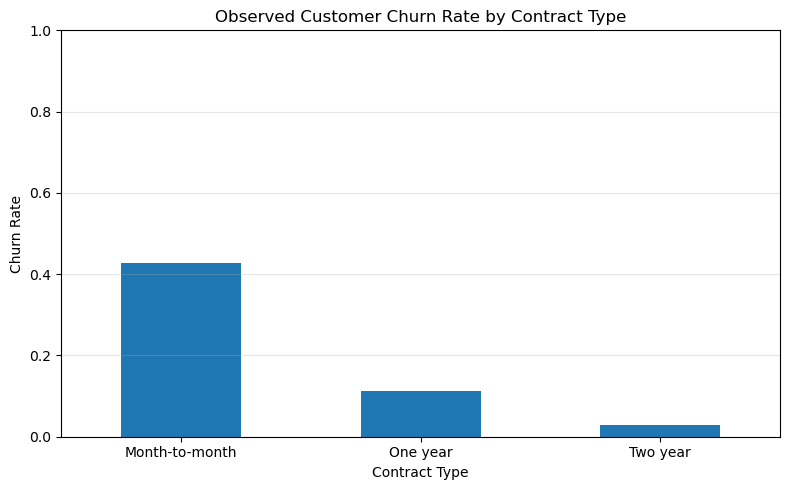

In [ ]:
# Churn Rate by Contract Type

contract_churn = (
    df_clean.groupby("Contract", observed=False)["Churn"]
    .agg(
        Total_Customers="count",
        Churned_Customers=lambda x: (x == "Yes").sum()
    )
)

contract_churn["Churn_Rate"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Total_Customers"]
)

contract_churn = contract_churn.sort_values(
    "Churn_Rate", ascending=False
)

display(contract_churn.round(4))

# Visualize observed churn rates
import matplotlib.pyplot as plt

contract_churn["Churn_Rate"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Observed Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Key business insights
1. Month-to-month customers: 42.71% churn rate — the highest-risk contract group in this analysis.
2. One-year customers: 11.27% churn rate.
3. Two-year customers: 2.83% churn rate — the lowest churn rate.

The observed churn rate for month-to-month customers is about 15 times that of two-year customers. This is a strong association, although it does not prove that contract length alone causes churn.

Recommended business actions
- Target month-to-month customers with early retention offers and proactive customer-service follow-ups.
- Investigate whether flexible-contract customers are dissatisfied with pricing, service quality, or support.
- Test whether incentives for longer-term contracts improve retention without reducing profitability.

### Contract Type and Customer Churn Analysis

The analysis reveals substantial differences in churn rates across contract types. Month-to-month customers have the highest observed churn rate at **42.71%**, compared with **11.27%** for one-year contracts and **2.83%** for two-year contracts.

These findings suggest that customers on flexible contracts should be a priority segment for retention analysis and targeted interventions. Potential actions include proactive support, personalized retention offers, and investigating customer concerns related to pricing and service quality.

However, these are observational findings. Contract type may be associated with other customer characteristics, and the analysis does not establish causation. Retention interventions should therefore be tested and evaluated before their effectiveness is assumed.

### Select the preliminary final model

In [ ]:
# Final Model Comparison

final_model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.7381,
        "Precision": 0.5043,
        "Recall": 0.7834,
        "F1-Score": 0.6136,
        "ROC-AUC": 0.8413
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.7551,
        "Precision": 0.5269,
        "Recall": 0.7594,
        "F1-Score": 0.6221,
        "ROC-AUC": 0.8323
    },
    {
        "Model": "Random Forest (Original)",
        "Accuracy": 0.7637,
        "Precision": 0.5485,
        "Recall": 0.6203,
        "F1-Score": 0.5822,
        "ROC-AUC": 0.8225
    },
    {
        "Model": "Random Forest (Regularized)",
        "Accuracy": 0.7551,
        "Precision": 0.5253,
        "Recall": 0.8048,
        "F1-Score": 0.6357,
        "ROC-AUC": 0.8433
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.8013,
        "Precision": 0.6567,
        "Recall": 0.5267,
        "F1-Score": 0.5846,
        "ROC-AUC": 0.8447
    },
    {
        "Model": "Random Forest (Tuned)",
        "Accuracy": 0.7495,
        "Precision": 0.5185,
        "Recall": 0.7888,
        "F1-Score": 0.6257,
        "ROC-AUC": 0.8422
    }
])

display(
    final_model_comparison
    .sort_values(by="F1-Score", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest (Regularized),0.7551,0.5253,0.8048,0.6357,0.8433
1,Random Forest (Tuned),0.7495,0.5185,0.7888,0.6257,0.8422
2,Decision Tree,0.7551,0.5269,0.7594,0.6221,0.8323
3,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
4,XGBoost,0.8013,0.6567,0.5267,0.5846,0.8447
5,Random Forest (Original),0.7637,0.5485,0.6203,0.5822,0.8225


### Save the selected model

In [ ]:
# Save the selected churn prediction model

import joblib
from pathlib import Path

# Create a folder for saved model artifacts
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save the complete preprocessing and prediction pipeline
final_model = random_forest_regularized

model_path = model_dir / "churn_random_forest_pipeline.joblib"
joblib.dump(final_model, model_path)

print("Model saved successfully.")
print(f"Model location: {model_path.resolve()}")
print(f"Model type: {type(final_model).__name__}")

Model saved successfully.
Model location: C:\Users\admin\Documents\Arnold-Kirwa projects\telecom-churn-risk-analysis\models\churn_random_forest_pipeline.joblib
Model type: Pipeline
